# African Asylum Seekers & Immigration Flows to the USA — Exploratory Data Analysis

**Domain:** Immigration · **Geography:** Africa & USA · **Period:** 2021–2025

This notebook explores the SQLite warehouse built by the pipeline
(`ingest.py → transform.py → load.py`). The data comes from the **World Bank Open Data API**:

| Indicator | Code |
|---|---|
| Net migration | `SM.POP.NETM` |
| International migrant stock | `SM.POP.TOTL` |
| Migrant stock (% of population) | `SM.POP.TOTL.ZS` |
| Personal remittances received (% of GDP) | `BX.TRF.PWKR.DT.GD.ZS` |

Asylum-specific context comes from the [UNHCR Refugee Data Finder](https://www.unhcr.org/refugee-statistics/)
and the [DHS Yearbook of Immigration Statistics](https://www.dhs.gov/immigration-statistics/yearbook).

> **Reading the numbers:** World Bank *net migration* counts all destinations. A negative value means more
> people left the country than arrived — this outflow is the pool from which US-bound migrants and asylum
> seekers originate.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
pio.renderers.default = "notebook_connected"  # load plotly.js from CDN to keep the notebook small
pd.set_option("display.float_format", "{:,.2f}".format)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = PROJECT_ROOT / "data" / "africa_usa_immigration.db"
if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH} not found - run the pipeline first (see README).")

conn = sqlite3.connect(DB_PATH)
migration = pd.read_sql("SELECT * FROM migration_flows", conn)
remittances = pd.read_sql("SELECT * FROM remittance_flows", conn)
profiles = pd.read_sql("SELECT * FROM country_profiles", conn)
africa = migration[migration["region"] == "Africa"].copy()
usa = migration[migration["region"] == "USA"].copy()
print(f"migration_flows: {len(migration)} rows | remittance_flows: {len(remittances)} rows | "
      f"country_profiles: {len(profiles)} rows")
print(f"African countries: {africa['iso3'].nunique()} | years: {migration['year'].min()}-{migration['year'].max()}")

migration_flows: 270 rows | remittance_flows: 70 rows | country_profiles: 54 rows
African countries: 53 | years: 2021-2025


## 1. Data quality overview

Net migration is complete for every country-year. Migrant stock is published by the World Bank only for
benchmark years, so the transformation stage carries the nearest reported value across years
(`migrant_stock_filled`). Remittances are missing for some country-years.

In [2]:
quality = pd.DataFrame({
    "table": ["migration_flows"] * 3 + ["remittance_flows"] * 2,
    "column": ["net_migration", "migrant_stock_total", "migrant_stock_filled",
               "remittances_pct_gdp", "migrant_stock_total"],
    "non_null": [migration["net_migration"].notna().sum(), migration["migrant_stock_total"].notna().sum(),
                 migration["migrant_stock_filled"].notna().sum(), remittances["remittances_pct_gdp"].notna().sum(),
                 remittances["migrant_stock_total"].notna().sum()],
})
quality["rows"] = [len(migration)] * 3 + [len(remittances)] * 2
quality["completeness_pct"] = 100 * quality["non_null"] / quality["rows"]
quality

,table,column,non_null,rows,completeness_pct
0,migration_flows,net_migration,270,270,100.00
1,migration_flows,migrant_stock_total,14,270,5.19
2,migration_flows,migrant_stock_filled,70,270,25.93
3,remittance_flows,remittances_pct_gdp,49,70,70.00
4,remittance_flows,migrant_stock_total,14,70,20.00


## 2. Top 10 African countries by cumulative net emigration (2021–2025)

Which African countries lose the most people to migration? These are the largest origin pools for migrants
and asylum seekers heading to destinations including the United States.

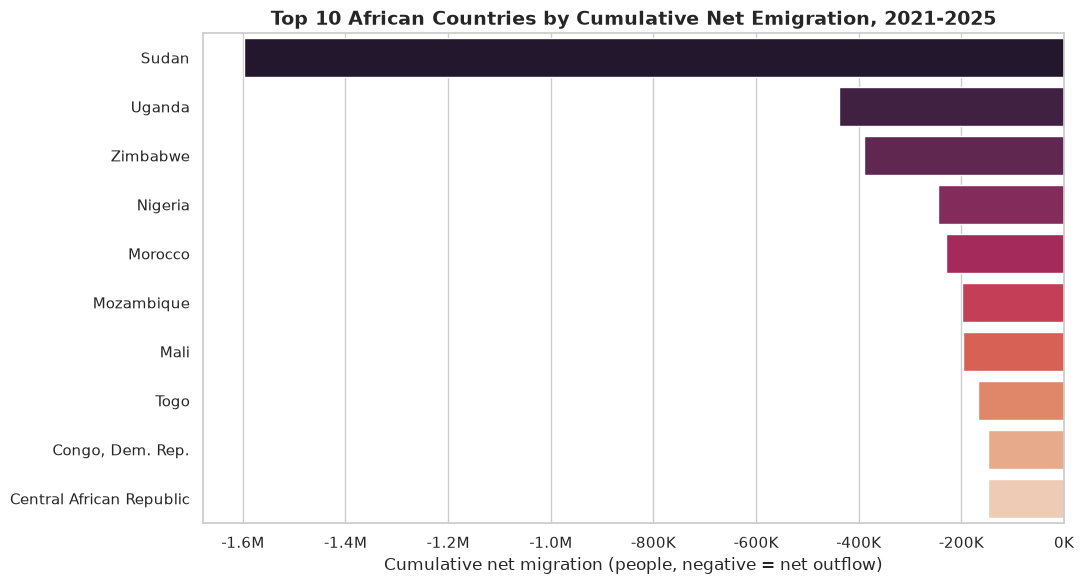

,country_name,net_migration
0,Sudan,"-1,597,790.00"
1,Uganda,"-438,543.00"
2,Zimbabwe,"-389,914.00"
3,Nigeria,"-246,191.00"
4,Morocco,"-229,202.00"
5,Mozambique,"-198,828.00"
6,Mali,"-197,013.00"
7,Togo,"-167,247.00"
8,"Congo, Dem. Rep.","-148,899.00"
9,Central African Republic,"-147,808.00"


In [3]:
top_emigration = (africa.groupby("country_name")["net_migration"].sum()
                        .sort_values().head(10).reset_index())
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=top_emigration, y="country_name", x="net_migration", hue="country_name",
            palette="rocket", legend=False, ax=ax)
ax.set_title("Top 10 African Countries by Cumulative Net Emigration, 2021-2025", fontsize=14, weight="bold")
ax.set_xlabel("Cumulative net migration (people, negative = net outflow)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e6:,.1f}M" if abs(v) >= 1e6 else f"{v / 1e3:,.0f}K"))
plt.tight_layout()
plt.show()
top_emigration

**Finding:** Sudan dominates African outflows — roughly **-1.6 million** net over five years, driven by the
April-2023 civil war (its single worst year is about -1.35 million). Uganda, Zimbabwe, Nigeria and Morocco
follow. Conflict (Sudan, CAR, DRC) and economic pressure (Zimbabwe, Nigeria) are both visible in the list —
the same push factors behind asylum claims recorded by UNHCR and DHS.

## 3. Migration trends over time: Africa vs the USA

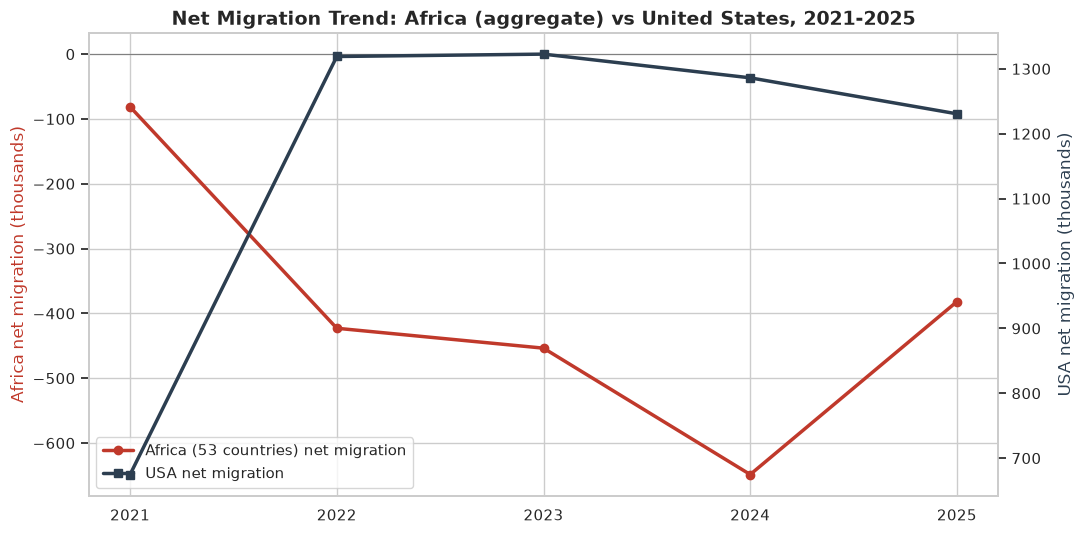

region,year,Africa,USA
0,2021,"-81,296.00","674,787.00"
1,2022,"-422,927.00","1,319,009.00"
2,2023,"-453,629.00","1,322,668.00"
3,2024,"-648,557.00","1,286,132.00"
4,2025,"-381,865.00","1,230,663.00"


In [4]:
trend = (migration.groupby(["year", "region"])["net_migration"].sum()
                  .unstack("region").reset_index())
fig, ax1 = plt.subplots(figsize=(11, 5.5))
ax1.plot(trend["year"], trend["Africa"] / 1e3, marker="o", color="#c0392b", linewidth=2.5,
         label="Africa (53 countries) net migration")
ax1.axhline(0, color="grey", linewidth=0.8)
ax1.set_ylabel("Africa net migration (thousands)", color="#c0392b")
ax2 = ax1.twinx()
ax2.plot(trend["year"], trend["USA"] / 1e3, marker="s", color="#2c3e50", linewidth=2.5,
         label="USA net migration")
ax2.set_ylabel("USA net migration (thousands)", color="#2c3e50")
ax2.grid(False)
ax1.set_xticks(trend["year"])
ax1.set_title("Net Migration Trend: Africa (aggregate) vs United States, 2021-2025", fontsize=14, weight="bold")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="lower left")
plt.tight_layout()
plt.show()
trend

In [5]:
top5 = africa.groupby("country_name")["net_migration"].sum().nsmallest(5).index
fig = px.line(africa[africa["country_name"].isin(top5)], x="year", y="net_migration", color="country_name",
              markers=True, title="Net Migration Trajectories of the 5 Largest African Emigration Countries",
              labels={"net_migration": "Net migration (people)", "year": "Year", "country_name": "Country"})
fig.add_hline(y=0, line_dash="dot", line_color="grey")
fig.show()

**Finding:** Aggregate African net migration stayed negative every year and deepened from about **-81K
(2021)** to about **-649K (2024)** before easing to about **-382K in 2025**. US net migration nearly doubled
from about **675K (2021)** to about **1.32M (2022–2023)**, then softened slightly to about **1.23M in 2025** —
the United States remains the world's largest single destination absorbing the global migrant flow that
includes African asylum seekers.

## 4. Heatmap of net migration by country and year

A country × year heatmap reveals volatility that annual totals hide (sudden conflict-driven outflows).

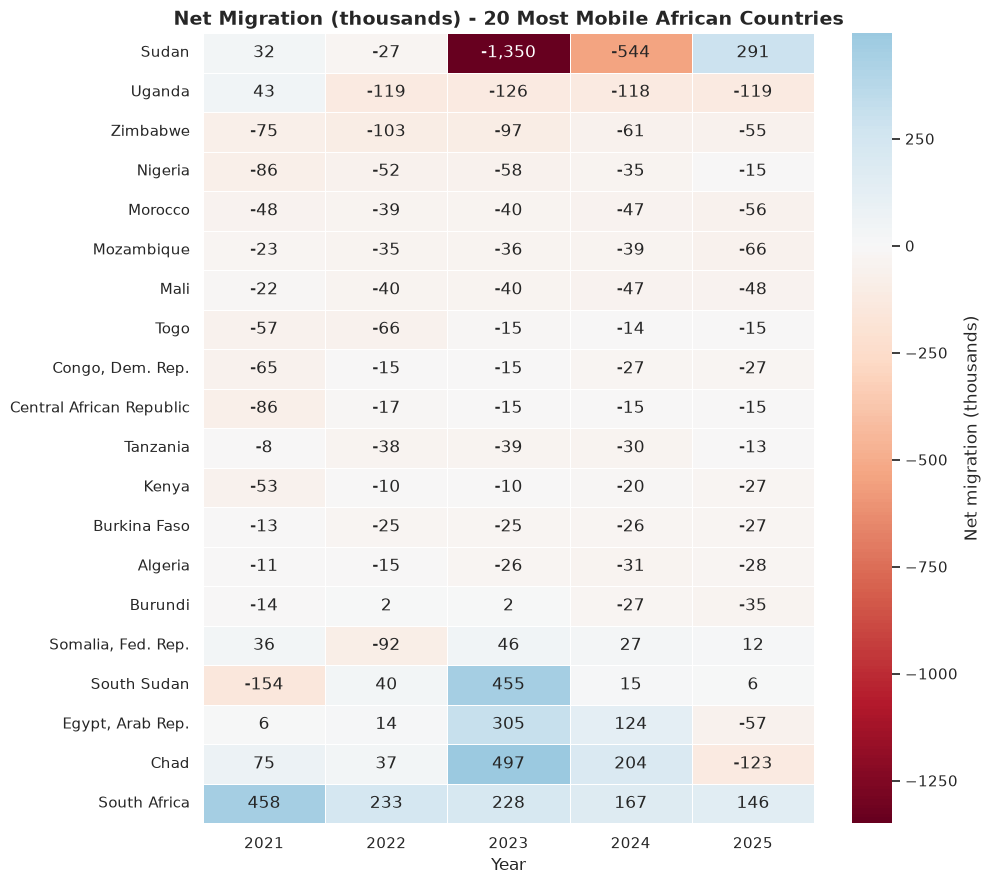

In [6]:
top20 = africa.groupby("country_name")["net_migration"].apply(lambda s: s.abs().sum()).nlargest(20).index
heat = (africa[africa["country_name"].isin(top20)]
        .pivot_table(index="country_name", columns="year", values="net_migration")
        .loc[lambda d: d.sum(axis=1).sort_values().index])
fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(heat / 1e3, cmap="RdBu", center=0, annot=True, fmt=",.0f", linewidths=0.4,
            cbar_kws={"label": "Net migration (thousands)"}, ax=ax)
ax.set_title("Net Migration (thousands) - 20 Most Mobile African Countries", fontsize=14, weight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 5. Choropleth of international migrant stock (latest reported year)

Where do migrants already live in Africa? Migrant stock (`SM.POP.TOTL`) is reported for a subset of countries;
grey countries have no reported value in the current extract.

In [7]:
stock_map = profiles[(profiles["region"] == "Africa") & profiles["latest_migrant_stock"].notna()]
fig = px.choropleth(stock_map, locations="iso3", color="latest_migrant_stock", hover_name="country_name",
                    hover_data={"latest_migrant_stock_pct_pop": ":.1f", "iso3": False},
                    color_continuous_scale="Viridis", scope="africa",
                    labels={"latest_migrant_stock": "Migrant stock",
                            "latest_migrant_stock_pct_pop": "% of population"},
                    title="International Migrant Stock by African Country (latest World Bank value)")
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig.show()
stock_map[["country_name", "latest_migrant_stock", "latest_migrant_stock_pct_pop"]].sort_values(
    "latest_migrant_stock", ascending=False)

,country_name,latest_migrant_stock,latest_migrant_stock_pct_pop
6,Cote d'Ivoire,"2,880,839.00",9.00
45,Chad,"1,269,673.00",6.30
8,"Congo, Dem. Rep.","1,085,090.00",1.00
3,Burkina Faso,"739,820.00",3.10
0,Angola,"676,507.00",1.80
7,Cameroon,"642,948.00",2.20
2,Benin,"418,202.00",2.90
1,Burundi,"387,101.00",2.80
9,"Congo, Rep.","385,589.00",6.10
13,Algeria,"259,458.00",0.60


**Finding:** Côte d'Ivoire hosts the largest migrant stock in the extract (~**2.88M**, **9%** of its
population), followed by Chad (~1.27M, swelled by Sudanese refugees) and the DRC (~1.09M). African migration is
largely *intra-regional*: many people displaced by conflict settle in neighbouring countries before any
onward movement to the USA or Europe.

## 6. Remittances vs migrant stock

Remittances measure how strongly an economy depends on its diaspora — a proxy for established migration
corridors (including to the USA).

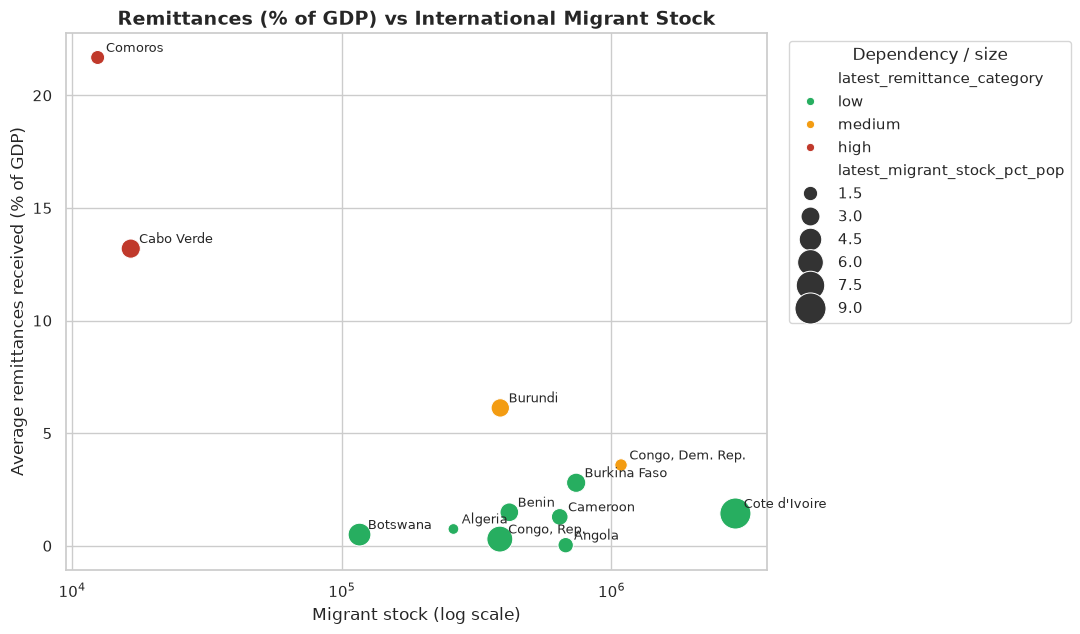

Pearson r (migrant stock vs remittances % GDP): -0.339 across 12 countries


In [8]:
scatter = profiles.dropna(subset=["latest_migrant_stock", "avg_remittances_pct_gdp"])
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.scatterplot(data=scatter, x="latest_migrant_stock", y="avg_remittances_pct_gdp",
                hue="latest_remittance_category", size="latest_migrant_stock_pct_pop", sizes=(60, 500),
                palette={"high": "#c0392b", "medium": "#f39c12", "low": "#27ae60"}, ax=ax)
for _, row in scatter.iterrows():
    ax.annotate(row["country_name"], (row["latest_migrant_stock"], row["avg_remittances_pct_gdp"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xscale("log")
ax.set_title("Remittances (% of GDP) vs International Migrant Stock", fontsize=14, weight="bold")
ax.set_xlabel("Migrant stock (log scale)")
ax.set_ylabel("Average remittances received (% of GDP)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Dependency / size")
plt.tight_layout()
plt.show()
r = scatter["latest_migrant_stock"].corr(scatter["avg_remittances_pct_gdp"])
print(f"Pearson r (migrant stock vs remittances % GDP): {r:.3f} across {len(scatter)} countries")

**Finding:** The relationship is weakly *negative* (Pearson r ≈ **-0.34**). Small island states with
large diasporas abroad — **Comoros (~21.7% of GDP)** and **Cabo Verde (~13.2%)** — are the most
remittance-dependent, while large migrant *host* countries such as Côte d'Ivoire receive little. Remittance
dependency reflects people who have **left**, not people who live there.

## 7. Regional distribution of African net emigration

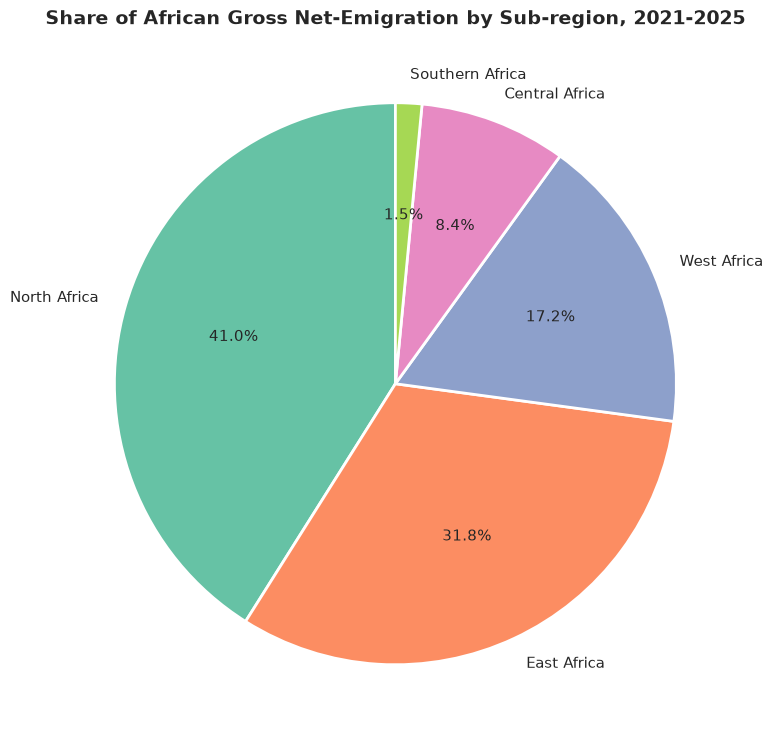

,gross_net_emigration
subregion,
North Africa,"2,389,455.00"
East Africa,"1,851,862.00"
West Africa,"999,808.00"
Central Africa,"491,885.00"
Southern Africa,"88,127.00"


In [9]:
regional = (africa[africa["net_migration"] < 0]
            .groupby("subregion")["net_migration"].sum().abs().sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(8, 8))
colors = sns.color_palette("Set2", len(regional))
ax.pie(regional, labels=regional.index, autopct="%1.1f%%", startangle=90, colors=colors,
       wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 11})
ax.set_title("Share of African Gross Net-Emigration by Sub-region, 2021-2025", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()
regional.rename("gross_net_emigration").to_frame()

**Finding:** North Africa (driven by Sudan) and East Africa together account for nearly 90% of
Africa's gross net emigration over 2021–2025. West Africa — historically a major source of African
immigrants to the USA (Nigeria, Ghana, Senegal) — contributes about one fifth.

## 8. Remittance dependency categories

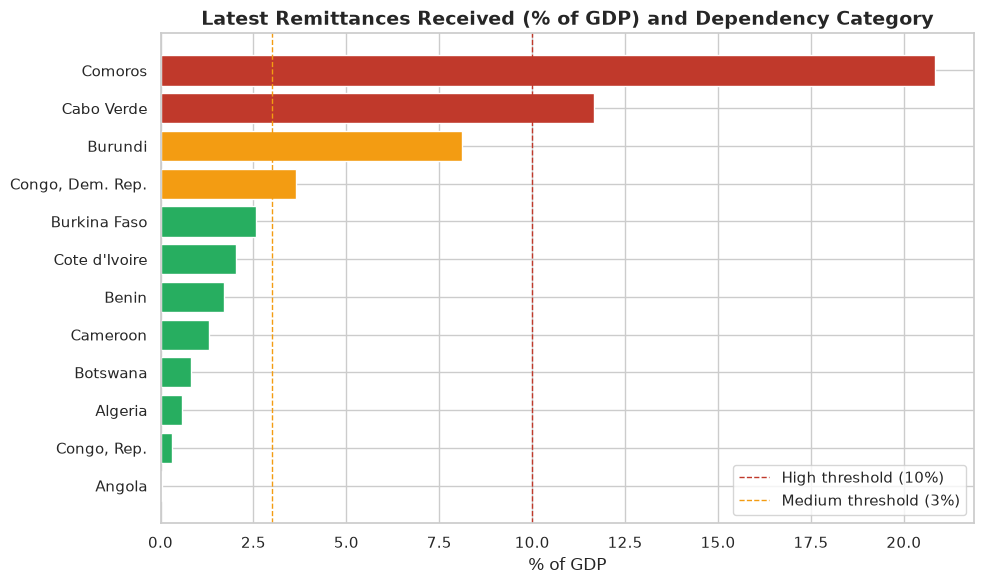

In [10]:
latest_remit = (remittances.dropna(subset=["remittances_pct_gdp"]).sort_values("year")
                           .groupby("country_name").tail(1).sort_values("remittances_pct_gdp"))
fig, ax = plt.subplots(figsize=(10, 6))
palette = {"high": "#c0392b", "medium": "#f39c12", "low": "#27ae60"}
ax.barh(latest_remit["country_name"], latest_remit["remittances_pct_gdp"],
        color=latest_remit["remittance_dependency_category"].map(palette))
ax.axvline(10, color="#c0392b", linestyle="--", linewidth=1, label="High threshold (10%)")
ax.axvline(3, color="#f39c12", linestyle="--", linewidth=1, label="Medium threshold (3%)")
ax.set_title("Latest Remittances Received (% of GDP) and Dependency Category", fontsize=14, weight="bold")
ax.set_xlabel("% of GDP")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Key takeaways

1. **Sudan is the epicentre of African displacement** — about -1.6M cumulative net migration in 2021–2025,
   with its 2023 conflict outflow the largest single-year movement in the dataset.
2. **Africa is a persistent net-emigration continent** — aggregate net migration was negative in every year,
   peaking at about -649K in 2024.
3. **The USA absorbed 1.2–1.3M net migrants per year since 2022**, around twice its 2021 level, making it the
   key long-haul destination for African migrants and asylum seekers.
4. **Most African migration stays in Africa** — host countries such as Côte d'Ivoire and Chad carry the
   largest migrant stocks.
5. **Diaspora economies are small and island-based** — Comoros and Cabo Verde rely on remittances for
   13–22% of GDP, while remittances correlate weakly (and negatively) with migrant stock.

**Limitations:** World Bank net migration is not destination-specific, migrant stock is only available for
benchmark years and a subset of countries in this extract, and asylum application counts must be joined from
UNHCR / DHS sources for a full asylum picture.

In [11]:
conn.close()